<a href="https://colab.research.google.com/github/aishahifritcd24-star/DLG_lab/blob/main/1BM24CD003_AishahIfrit_Program_6(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow: 2.21.0
x_train: (1000, 29, 50)  y_train: (1000, 29, 50)
Task 1 looks correct ✔


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 339ms/step - accuracy: 0.1106 - loss: 3.8841 - val_accuracy: 0.1753 - val_loss: 3.8433
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.1446 - loss: 3.7708 - val_accuracy: 0.0993 - val_loss: 3.6489
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 325ms/step - accuracy: 0.1184 - loss: 3.5160 - val_accuracy: 0.1405 - val_loss: 3.3971
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 286ms/step - accuracy: 0.1628 - loss: 3.2351 - val_accuracy: 0.1731 - val_loss: 3.1120
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 368ms/step - accuracy: 0.2101 - loss: 2.8928 - val_accuracy: 0.2345 - val_loss: 2.7318
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 285ms/step - accuracy: 0.2739 - loss: 2.5119 - val_accuracy: 0.3048 - val_loss: 2.3548
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 271ms/step - accuracy: 0.3463 - loss: 2.1300 - val_accuracy: 0.3771 - val_loss: 1.9880
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 378ms/step - accuracy: 0.4256 - loss: 1.7721 - val_accuracy: 0

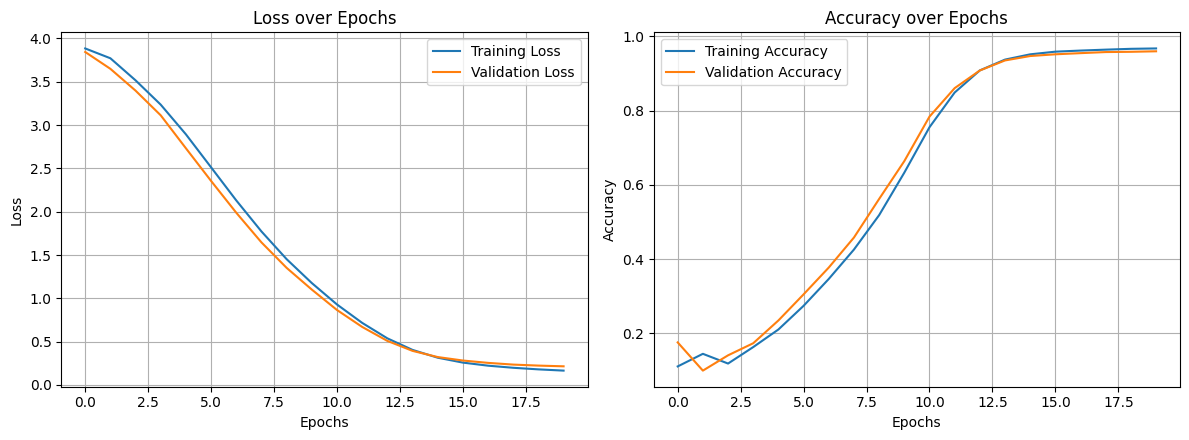

Generated: [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


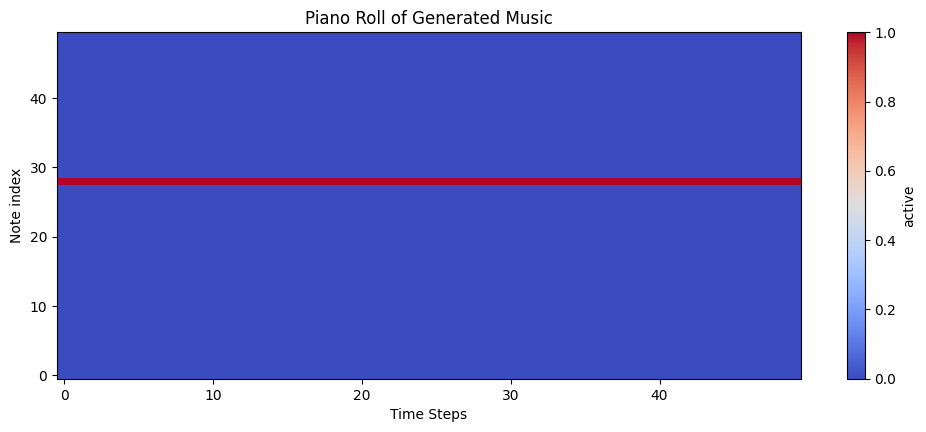

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

num_notes       = 50
sequence_length = 30
num_sequences   = 1000

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))

# Q1a)
x_train = data[:, :-1]
y_train = data[:, 1:]

# Q1b)
NUM_CLASSES = num_notes
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)

assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")


model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))

# Q2a)
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))

# Q2b)
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))

# Q2c)
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))

model.summary()


# Q3a)
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Q3b)
history = model.fit(x_train, y_train,
                    epochs=20,
                    batch_size=64,
                    validation_split=0.2)


plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()


def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)

        # Q5a)
        next_note = np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated


start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)


piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()